# 06 · Final evaluation on the test window

Supports **Sections 7.1–7.7, 7.9 and 7.10** of the thesis. This is the first and only use of the test window
(23.05.–19.06.2016.). Every model was fixed before it was opened: the classical methods have
no tuned parameters, and each XGBoost model is its best validation trial refitted on targets up to 22.05.2016.
The one exception is the input set L+E+S+ID+H, which was added afterwards and tuned on the validation window
only. It is therefore reported as an additional step of the input analysis, and the **main model** is the
variant with the lowest validation WRMSSE among those fixed beforehand.
The forecasts are built by `python src/evaluation.py`; this notebook only scores them.

As on the validation window, the 28 days are forecast 7 days at a time from 4 weekly origins, without
refitting. The scales and weights of RMSSE and WRMSSE are the official M5 ones (history up to 22.05.2016.).

Two measures are reported throughout, because they answer different questions:

- **WRMSSE**: the M5 score, the mean over the 12 hierarchy levels of the revenue-weighted RMSSE of the
  aggregated forecasts. It rewards getting totals right.
- **Mean RMSSE**: the unweighted mean of RMSSE over the 30,490 item × store series. It measures accuracy on
  single series, most of which are intermittent.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import evaluation as E
import factorial_stats as S
import m5_data as m5
import metrics as M
from plot_style import CONTEXT, INK_SECONDARY, SERIES, apply_style, savefig

apply_style()
pd.set_option("display.float_format", "{:,.3f}".format)
RESULTS = ROOT / "results" / "evaluation"
RESULTS.mkdir(parents=True, exist_ok=True)
RUNS = m5.PROCESSED_DIR / "global_xgb"

INPUTS = {"L": "L", "LE": "L+E", "LES": "L+E+S", "LESID": "L+E+S+ID", "LESIDH": "L+E+S+ID+H"}
LOSSES = {"mse": "MSE", "poisson": "Poisson", "tweedie": "Tweedie"}
KINDS = {"": "", "per_store": "per store", "per_store_cat": "per store × category", "per_class": "per demand class",
         "recursive": "recursive"}
BM = {"naive": "Naive", "snaive": "Seasonal naive", "mean": "Mean", "croston": "Croston", "sba": "SBA", "tsb": "TSB",
      "adida": "ADIDA", "ses": "SES", "ses_opt": "SES (optimised)", "sba_opt": "SBA (optimised)", "tsb_opt": "TSB (optimised)"}
LEVEL_NAMES = {1: "Total", 2: "State", 3: "Store", 4: "Category", 5: "Department", 6: "State × category",
               7: "State × department", 8: "Store × category", 9: "Store × department", 10: "Item",
               11: "Item × state", 12: "Item × store"}
CLASSES = ["smooth", "erratic", "intermittent", "lumpy"]


def label(key):
    if key.startswith("benchmark_"):
        return BM[key[10:]]
    inputs, loss, *rest = key.split("_", 2)
    kind = KINDS[rest[0]] if rest else ""
    return f"{INPUTS[inputs]} · {LOSSES[loss]}" + (f" · {kind}" if kind else "")


raw = np.load(E.OUT)
test = {label(k): raw[k] for k in raw.files if not k.startswith(("sample_", "backtest_")) and "_seed" not in k}
seeds_fc = {k: raw[k] for k in raw.files if "_seed" in k}
sample_fc = {k[7:]: raw[k] for k in raw.files if k.startswith("sample_")}

valid = {BM[m]: f for m, f in ((k[6:], v) for k, v in np.load(m5.PROCESSED_DIR / "forecasts" / "benchmarks.npz").items())}
for f in RUNS.glob("*/*/valid_forecast.npy"):
    valid[label(f.parent.name)] = np.load(f)
assert set(valid) == set(test)

ev_test = E.test_evaluator()
ev_valid = M.Evaluator.for_origin(m5.TRAIN_END, (m5.TRAIN_END + 1, m5.VALID_END))
stats = pd.read_parquet(m5.PROCESSED_DIR / "series_stats_train.parquet")
cls = stats["sbc_class"].astype(str).to_numpy()

XGB = [m for m in test if m not in BM.values()]
GLOBAL = sorted([m for m in XGB if m.count("·") == 1],
                key=lambda m: (list(INPUTS.values()).index(m.split(" · ")[0]), list(LOSSES.values()).index(m.split(" · ")[1])))
OTHER = [m for m in XGB if m not in GLOBAL]
ORDER = list(BM.values()) + GLOBAL + sorted(OTHER)
print(f"{len(BM)} classical methods, {len(GLOBAL)} global variants, {len(OTHER)} partially global and recursive models")

C:\Users\ilin.j\AppData\Roaming\Python\Python312\site-packages\hyperopt\atpe.py:19: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


11 classical methods, 11 global variants, 8 partially global and recursive models


## 1. All models: validation and test (Sections 7.1, 7.3, 7.4)

The validation columns are optimistic for the XGBoost models, which were tuned on that window. The test
columns are the result.

In [2]:
score = {w: {m: ev.wrmsse(fc[m]) for m in ORDER} for w, ev, fc in [("valid", ev_valid, valid), ("test", ev_test, test)]}
bottom = {w: {m: ev.bottom(fc[m]) for m in ORDER} for w, ev, fc in [("valid", ev_valid, valid), ("test", ev_test, test)]}
rmsse = pd.DataFrame({m: bottom["test"][m]["rmsse"] for m in ORDER})
summary = pd.DataFrame({"WRMSSE valid": {m: score["valid"][m]["all"] for m in ORDER},
                        "WRMSSE test": {m: score["test"][m]["all"] for m in ORDER},
                        "RMSSE mean valid": {m: bottom["valid"][m]["rmsse"].mean() for m in ORDER},
                        "RMSSE mean test": rmsse.mean(), "RMSSE median test": rmsse.median(),
                        "MASE mean test": {m: bottom["test"][m]["mase"].mean() for m in ORDER},
                        "bias test (scaled mean error)": {m: bottom["test"][m]["sme"].mean() for m in ORDER}})
summary.to_csv(RESULTS / "summary_test.csv")
out = rmsse.copy()
out.insert(0, "id", stats["id"].to_numpy())
out.to_csv(RESULTS / "rmsse_test.csv", index=False, float_format="%.5f")
EXTRA = "L+E+S+ID+H · Tweedie"  # added after the test window had been opened: an additional step, not the main model
# the main model: chosen on the validation window, not on the test window, among the variants fixed before the test window was opened
BEST = summary.loc[[m for m in GLOBAL if m != EXTRA], "WRMSSE valid"].idxmin()
MAIN = "L+E+S+ID · Tweedie"  # the variant whose hyperparameters the partially global and recursive models use
assert BEST == MAIN
print("main model (lowest validation WRMSSE of the variants fixed before the test window):", BEST)
summary.style.format("{:.3f}").background_gradient(cmap="Blues_r", subset=["WRMSSE test"]).background_gradient(
    cmap="Blues_r", subset=["RMSSE mean test"])

main model (lowest validation WRMSSE of the variants fixed before the test window): L+E+S+ID · Tweedie


,WRMSSE valid,WRMSSE test,RMSSE mean valid,RMSSE mean test,RMSSE median test,MASE mean test,bias test (scaled mean error)
Naive,1.753,1.605,1.043,1.050,0.954,1.327,0.199
Seasonal naive,0.924,0.901,1.011,1.033,0.965,1.241,0.001
Mean,1.206,1.081,0.793,0.797,0.708,1.112,-0.166
Croston,1.068,0.972,0.766,0.773,0.712,1.100,-0.001
SBA,1.094,0.961,0.765,0.771,0.711,1.084,-0.054
TSB,1.064,0.956,0.755,0.766,0.713,1.089,0.018
ADIDA,1.066,0.945,0.753,0.762,0.706,1.071,-0.040
SES,1.066,0.961,0.757,0.768,0.715,1.092,0.022
SES (optimised),1.075,0.962,0.756,0.765,0.711,1.088,0.020
SBA (optimised),1.111,0.961,0.765,0.771,0.711,1.084,-0.054


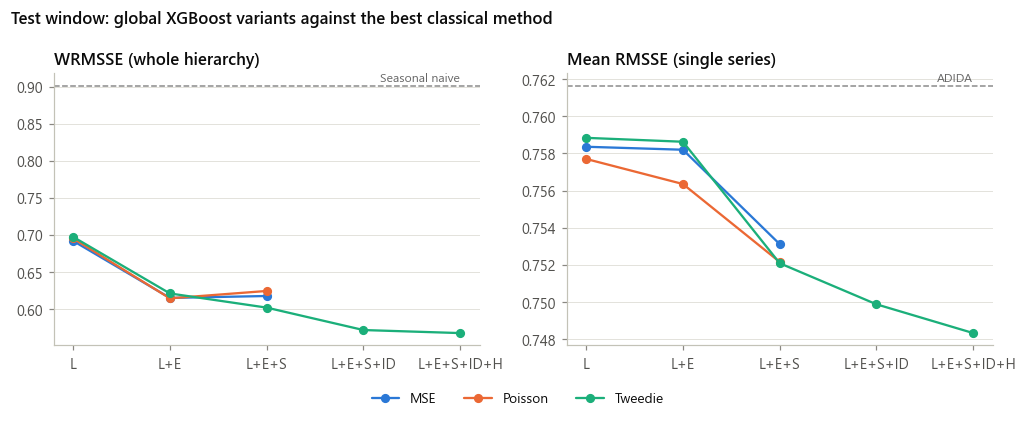

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
sets = list(INPUTS.values())
for ax, col, title in zip(axes, ["WRMSSE test", "RMSSE mean test"], ["WRMSSE (whole hierarchy)", "Mean RMSSE (single series)"]):
    for loss, color in zip(LOSSES.values(), SERIES):
        v = [summary.loc[f"{i} · {loss}", col] if f"{i} · {loss}" in summary.index else np.nan for i in sets]
        ax.plot(range(len(sets)), v, color=color, marker="o", ms=5, label=loss)
    ref = "Seasonal naive" if col.startswith("WRMSSE") else summary.loc[list(BM.values()), col].idxmin()
    ax.axhline(summary.loc[ref, col], color="0.55", lw=1, ls="--")
    ax.annotate(ref, (len(sets) - 1, summary.loc[ref, col]), xytext=(0, 3), textcoords="offset points", ha="right",
                color="0.4", fontsize=8)
    ax.set_xticks(range(len(sets)), sets)
    ax.set_title(title)
fig.suptitle("Test window: global XGBoost variants against the best classical method", x=0.01, ha="left", fontsize=11,
             fontweight="semibold")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.02), ncols=3)
savefig(fig, "variants_test", subdir="evaluation")
plt.show()

## 2. By hierarchy level (Section 7.6)

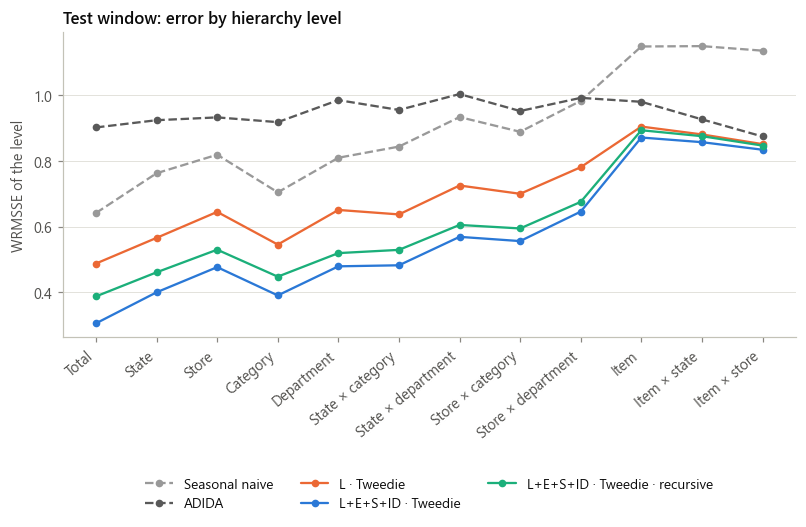

,Total,State,Store,Category,Department,State × category,State × department,Store × category,Store × department,Item,Item × state,Item × store
Seasonal naive,0.641,0.762,0.818,0.704,0.809,0.843,0.933,0.888,0.982,1.148,1.149,1.135
ADIDA,0.901,0.923,0.932,0.918,0.985,0.955,1.003,0.951,0.991,0.979,0.926,0.874
TSB,0.921,0.939,0.946,0.938,1.004,0.971,1.018,0.964,1.002,0.974,0.924,0.874
L · Tweedie,0.487,0.565,0.645,0.545,0.650,0.637,0.725,0.700,0.780,0.904,0.880,0.851
L+E · Tweedie,0.304,0.450,0.561,0.408,0.540,0.551,0.656,0.641,0.733,0.891,0.874,0.847
L+E+S · Tweedie,0.275,0.424,0.545,0.387,0.514,0.527,0.631,0.625,0.716,0.880,0.864,0.839
L+E+S+ID · Tweedie,0.305,0.400,0.476,0.390,0.479,0.482,0.569,0.556,0.645,0.871,0.857,0.834
L+E+S+ID+H · Tweedie,0.307,0.398,0.474,0.387,0.477,0.477,0.562,0.552,0.643,0.858,0.850,0.829
L+E+S+ID · Tweedie · recursive,0.387,0.461,0.530,0.447,0.519,0.529,0.605,0.594,0.675,0.893,0.875,0.846


In [4]:
levels = pd.DataFrame({m: score["test"][m].drop("all") for m in ORDER}).T
levels.columns = [LEVEL_NAMES[int(c)] for c in levels.columns]
levels.to_csv(RESULTS / "wrmsse_by_level_test.csv")
SHOW = ["Seasonal naive", "ADIDA", "TSB", "L · Tweedie", "L+E · Tweedie", "L+E+S · Tweedie", BEST, EXTRA, f"{MAIN} · recursive"]
fig, ax = plt.subplots(figsize=(8.6, 3.6))
colors = {"Seasonal naive": "0.6", "ADIDA": "0.35", BEST: SERIES[0], "L · Tweedie": SERIES[1], f"{MAIN} · recursive": SERIES[2]}
for m in ["Seasonal naive", "ADIDA", "L · Tweedie", BEST, f"{MAIN} · recursive"]:
    ax.plot(range(12), levels.loc[m].to_numpy(), color=colors[m], marker="o", ms=4, label=m,
            ls="--" if m in BM.values() else "-")
ax.set_xticks(range(12), levels.columns, rotation=40, ha="right")
ax.set_ylabel("WRMSSE of the level")
ax.set_title("Test window: error by hierarchy level")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.42))
savefig(fig, "wrmsse_by_level_test", subdir="evaluation")
plt.show()
levels.loc[SHOW].style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=0)

## 3. By demand class (Section 7.5)

Mean RMSSE of the item × store series of each Syntetos–Boylan class, and the share of the series of the class
on which the main model has a lower RMSSE than ADIDA.

In [5]:
by_class = rmsse.groupby(cls).mean().T[CLASSES]
by_class.insert(0, "all", rmsse.mean())
by_class.to_csv(RESULTS / "rmsse_by_class_test.csv")
d = rmsse[BEST] - rmsse["ADIDA"]
wins = pd.DataFrame({"series": pd.Series(cls).value_counts(), f"{BEST} better than ADIDA": (d < 0).groupby(cls).mean(),
                     "tie": (d == 0).groupby(cls).mean(), "mean difference": d.groupby(cls).mean()}).loc[CLASSES]
display(by_class.loc[SHOW + ["Croston", "SBA"]].style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=0))
wins.style.format("{:.3f}").format("{:,.0f}", subset=["series"])

,all,smooth,erratic,intermittent,lumpy
Seasonal naive,1.033,0.961,0.916,1.059,0.972
ADIDA,0.762,0.751,0.721,0.773,0.726
TSB,0.766,0.751,0.723,0.779,0.726
L · Tweedie,0.759,0.730,0.702,0.774,0.719
L+E · Tweedie,0.759,0.728,0.700,0.774,0.718
L+E+S · Tweedie,0.752,0.721,0.694,0.767,0.713
L+E+S+ID · Tweedie,0.750,0.719,0.691,0.765,0.709
L+E+S+ID+H · Tweedie,0.748,0.715,0.688,0.764,0.708
L+E+S+ID · Tweedie · recursive,0.753,0.730,0.696,0.768,0.714
Croston,0.773,0.777,0.747,0.783,0.738


,series,L+E+S+ID · Tweedie better than ADIDA,tie,mean difference
smooth,"1,921",0.690,0.000,-0.032
erratic,874,0.690,0.000,-0.030
intermittent,"22,161",0.555,0.000,-0.008
lumpy,"5,534",0.589,0.000,-0.017


## 4. Local, partially global and global models (Section 7.2)

**All 30,490 series.** One model for all series, against one model per store, per store × category and per
demand class. The partially global models use the hyperparameters of the global model with the same inputs.

In [6]:
KEEP = ["Total", "Store", "Store × category", "Item × store"]
rows_ = []
for base in ["L+E+S · Tweedie", "L+E+S+ID · Tweedie"]:
    for kind, n in [("", 1), ("per store", 10), ("per store × category", 30), ("per demand class", 4)]:
        m = base + (f" · {kind}" if kind else "")
        rows_.append({"inputs": base.split(" · ")[0], "pooling": kind or "all series", "models": n,
                      "WRMSSE valid": summary.loc[m, "WRMSSE valid"], "WRMSSE test": summary.loc[m, "WRMSSE test"],
                      **{k: levels.loc[m, k] for k in KEEP}, "RMSSE mean test": summary.loc[m, "RMSSE mean test"]})
pooling = pd.DataFrame(rows_).set_index(["inputs", "pooling"])
pooling.to_csv(RESULTS / "pooling_test.csv")
pooling.style.format("{:.3f}").format("{:.0f}", subset=["models"])

**The sample of 1,000 series** (250 per demand class, notebook 05): one model per series against one model for
the 1,000 series and the model on all series. On the validation window the models per series looked far better
only because each was chosen on the days it was scored on; here no model has seen the days.

In [7]:
sample = pd.read_csv(ROOT / "results" / "local_xgb" / "sample.csv")
srow, scls = sample["row"].to_numpy(), sample["sbc_class"].to_numpy()
ev_s = E.test_evaluator(rows=srow)
s_rmsse = {}
for i in ["L", "LE", "LES"]:
    s_rmsse[("per series", INPUTS[i])] = ev_s.bottom(sample_fc[f"per_series_{i}"])["rmsse"].to_numpy()
for i in INPUTS:
    if f"sample_{i}" in sample_fc:
        s_rmsse[("sample (1,000 series)", INPUTS[i])] = ev_s.bottom(sample_fc[f"sample_{i}"])["rmsse"].to_numpy()
    s_rmsse[("all series", INPUTS[i])] = rmsse[f"{INPUTS[i]} · Tweedie"].to_numpy()[srow]
for k in ["per store", "per demand class"]:
    s_rmsse[(k, "L+E+S+ID")] = rmsse[f"L+E+S+ID · Tweedie · {k}"].to_numpy()[srow]
for m in ["Seasonal naive", "Croston", "SBA", "TSB", "ADIDA"]:
    s_rmsse[("classical", m)] = rmsse[m].to_numpy()[srow]
s_rmsse = pd.DataFrame(s_rmsse)
valid_s = pd.read_csv(ROOT / "results" / "local_xgb" / "summary_valid.csv", index_col=[0, 1])["mean"]
s_summary = pd.DataFrame({"mean valid": valid_s.reindex(s_rmsse.columns), "mean test": s_rmsse.mean(),
                          "median test": s_rmsse.median(), **{c: s_rmsse[scls == c].mean() for c in CLASSES}})
s_summary.to_csv(RESULTS / "sample_summary_test.csv")


def pair(a, b):
    d = s_rmsse[b] - s_rmsse[a]
    return {"first": " · ".join(a), "second": " · ".join(b), "mean first": s_rmsse[a].mean(), "mean second": s_rmsse[b].mean(),
            "mean difference": d.mean(), "second better (share of series)": (d < 0).mean()}


PAIRS = ([(("per series", i), ("all series", i)) for i in ["L", "L+E", "L+E+S"]] +
         [(("per series", i), ("sample (1,000 series)", i)) for i in ["L", "L+E", "L+E+S"]] +
         [(("sample (1,000 series)", i), ("all series", i)) for i in ["L", "L+E", "L+E+S", "L+E+S+ID"]] +
         [(("per series", "L+E+S"), ("all series", "L+E+S+ID")), (("classical", "ADIDA"), ("per series", "L+E+S")),
          (("classical", "ADIDA"), ("all series", "L+E+S+ID"))])
s_pairs = pd.DataFrame([pair(a, b) for a, b in PAIRS])
family = S.wilcoxon_holm(s_rmsse.set_axis([" · ".join(c) for c in s_rmsse.columns], axis=1),
                         {f"{r['first']} vs {r['second']}": (r["first"], r["second"]) for _, r in s_pairs.iterrows()})
s_pairs["p (Wilcoxon, Holm)"] = [family.loc[f"{r['first']} vs {r['second']}", "p_holm"] for _, r in s_pairs.iterrows()]
s_pairs.to_csv(RESULTS / "sample_pairs_test.csv", index=False)
display(s_summary.style.format("{:.3f}").background_gradient(cmap="Blues_r", subset=["mean test"]))
s_pairs.style.format("{:.3f}", subset=["mean first", "mean second", "mean difference", "p (Wilcoxon, Holm)"]).format(
    "{:.0%}", subset=["second better (share of series)"])

,first,second,mean first,mean second,mean difference,second better (share of series),"p (Wilcoxon, Holm)"
0,per series · L,all series · L,0.753,0.725,-0.028,59%,0.000
1,per series · L+E,all series · L+E,0.750,0.724,-0.026,60%,0.000
2,per series · L+E+S,all series · L+E+S,0.754,0.718,-0.036,62%,0.000
3,per series · L,"sample (1,000 series) · L",0.753,0.724,-0.028,59%,0.000
4,per series · L+E,"sample (1,000 series) · L+E",0.750,0.722,-0.028,59%,0.000
5,per series · L+E+S,"sample (1,000 series) · L+E+S",0.754,0.719,-0.036,59%,0.000
6,"sample (1,000 series) · L",all series · L,0.724,0.725,0.000,49%,1.000
7,"sample (1,000 series) · L+E",all series · L+E,0.722,0.724,0.002,49%,1.000
8,"sample (1,000 series) · L+E+S",all series · L+E+S,0.719,0.718,-0.001,51%,1.000
9,"sample (1,000 series) · L+E+S+ID",all series · L+E+S+ID,0.713,0.714,0.001,51%,1.000


## 5. Recursive against direct strategy (Section 7.7)

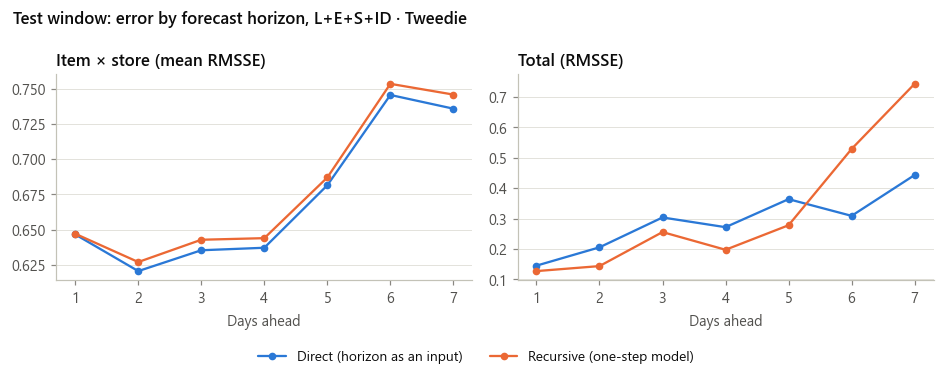

In [8]:
def by_horizon(f, ev):
    a = ev.actual[12]
    err = ((f - a) ** 2).reshape(len(a), m5.EVAL_WEEKS, m5.HORIZON).mean(axis=1)  # mean over the 4 origins
    item = np.sqrt(err / ev.scale[12][:, None]).mean(axis=0)
    tot = (f.sum(axis=0) - a.sum(axis=0)) ** 2
    total = np.sqrt(tot.reshape(m5.EVAL_WEEKS, m5.HORIZON).mean(axis=0) / ev.scale[1][0])
    return pd.DataFrame({"Item × store (mean RMSSE)": item, "Total (RMSSE)": total}, index=range(1, m5.HORIZON + 1))


strategy = pd.DataFrame([{"inputs": b.split(" · ")[0], "strategy": "recursive" if rec else "direct",
                          "WRMSSE valid": summary.loc[m, "WRMSSE valid"], "WRMSSE test": summary.loc[m, "WRMSSE test"],
                          **{k: levels.loc[m, k] for k in KEEP}, "RMSSE mean test": summary.loc[m, "RMSSE mean test"]}
                         for b in ["L+E+S · Tweedie", "L+E+S+ID · Tweedie"] for rec, m in [(False, b), (True, f"{b} · recursive")]]
                        ).set_index(["inputs", "strategy"])
strategy.to_csv(RESULTS / "strategy_test.csv")
direct, recursive = by_horizon(test[MAIN], ev_test), by_horizon(test[f"{MAIN} · recursive"], ev_test)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.1))
for ax, col in zip(axes, direct.columns):
    ax.plot(direct.index, direct[col], color=SERIES[0], marker="o", ms=4, label="Direct (horizon as an input)")
    ax.plot(recursive.index, recursive[col], color=SERIES[1], marker="o", ms=4, label="Recursive (one-step model)")
    ax.set_title(col)
    ax.set_xlabel("Days ahead")
fig.suptitle(f"Test window: error by forecast horizon, {MAIN}", x=0.01, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout()
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.5, 0.02), ncols=2)
savefig(fig, "strategy_by_horizon_test", subdir="evaluation")
plt.show()
strategy.style.format("{:.3f}")

## 6. Significance and stability (Section 7.9)

**Planned comparisons.** Two-sided Wilcoxon signed-rank tests on the RMSSE of the 30,490 series, with the Holm
correction over the family below. With this many series almost any difference is statistically significant,
so the size of the difference and the share of series on which the second model is better are given next
to the p-values.

In [9]:
T = "Tweedie"
PLANNED = {
    "7.1 main model vs seasonal naive": ("Seasonal naive", BEST),
    "7.1 main model vs ADIDA": ("ADIDA", BEST),
    "7.1 main model vs TSB": ("TSB", BEST),
    "7.1 lags only (L) vs ADIDA": ("ADIDA", f"L · {T}"),
    "7.3 Tweedie vs MSE (L+E+S)": ("L+E+S · MSE", f"L+E+S · {T}"),
    "7.3 Tweedie vs Poisson (L+E+S)": ("L+E+S · Poisson", f"L+E+S · {T}"),
    "7.4 L+E vs L": (f"L · {T}", f"L+E · {T}"),
    "7.4 L+E+S vs L+E": (f"L+E · {T}", f"L+E+S · {T}"),
    "7.4 L+E+S+ID vs L+E+S": (f"L+E+S · {T}", f"L+E+S+ID · {T}"),
    "7.4 L+E+S+ID+H vs L+E+S+ID": (f"L+E+S+ID · {T}", f"L+E+S+ID+H · {T}"),
    "7.2 all series vs per store": (f"{MAIN} · per store", MAIN),
    "7.2 all series vs per demand class": (f"{MAIN} · per demand class", MAIN),
    "7.7 recursive vs direct": (MAIN, f"{MAIN} · recursive"),
}
tests = S.wilcoxon_holm(rmsse, PLANNED).loc[list(PLANNED)]
tests["mean first"] = [rmsse[a].mean() for a in tests["A"]]
tests["mean second"] = [rmsse[b].mean() for b in tests["B"]]
tests["mean difference (second − first)"] = -tests["mean_diff"]
tests["second better (share of series)"] = [(rmsse[b] < rmsse[a]).mean() for a, b in zip(tests["A"], tests["B"])]
tests["WRMSSE first"] = [summary.loc[a, "WRMSSE test"] for a in tests["A"]]
tests["WRMSSE second"] = [summary.loc[b, "WRMSSE test"] for b in tests["B"]]
tests = tests.rename(columns={"A": "first", "B": "second"}).drop(columns=["mean_diff", "p_raw"])
tests = tests[["first", "second", "mean first", "mean second", "mean difference (second − first)",
               "second better (share of series)", "p_holm", "WRMSSE first", "WRMSSE second"]]
tests.to_csv(RESULTS / "planned_tests.csv")
tests.style.format("{:.3f}", subset=["mean first", "mean second", "WRMSSE first", "WRMSSE second"]).format(
    "{:+.4f}", subset=["mean difference (second − first)"]).format("{:.1%}", subset=["second better (share of series)"]).format(
    "{:.2g}", subset=["p_holm"])

,first,second,mean first,mean second,mean difference (second − first),second better (share of series),p_holm,WRMSSE first,WRMSSE second
contrast,,,,,,,,,
7.1 main model vs seasonal naive,Seasonal naive,L+E+S+ID · Tweedie,1.033,0.750,-0.2830,97.7%,0,0.901,0.572
7.1 main model vs ADIDA,ADIDA,L+E+S+ID · Tweedie,0.762,0.750,-0.0118,57.3%,1.3e-304,0.945,0.572
7.1 main model vs TSB,TSB,L+E+S+ID · Tweedie,0.766,0.750,-0.0158,67.4%,0,0.956,0.572
7.1 lags only (L) vs ADIDA,ADIDA,L · Tweedie,0.762,0.759,-0.0028,46.5%,4.7e-11,0.945,0.697
7.3 Tweedie vs MSE (L+E+S),L+E+S · MSE,L+E+S · Tweedie,0.753,0.752,-0.0010,52.7%,6.1e-28,0.618,0.602
7.3 Tweedie vs Poisson (L+E+S),L+E+S · Poisson,L+E+S · Tweedie,0.752,0.752,-0.0001,50.6%,0.028,0.625,0.602
7.4 L+E vs L,L · Tweedie,L+E · Tweedie,0.759,0.759,-0.0002,51.4%,0.00011,0.697,0.621
7.4 L+E+S vs L+E,L+E · Tweedie,L+E+S · Tweedie,0.759,0.752,-0.0065,61.9%,0,0.621,0.602
7.4 L+E+S+ID vs L+E+S,L+E+S · Tweedie,L+E+S+ID · Tweedie,0.752,0.750,-0.0022,54.4%,1.3e-79,0.602,0.572


**All models together.** Friedman test on the ranks of the models within each series (1 = lowest RMSSE), and
the Nemenyi critical difference: two models whose mean ranks differ by less than CD are not distinguishable.

Friedman chi2 = 86,434, p = 0; Nemenyi CD = 0.123 (15 models, 30,490 series)


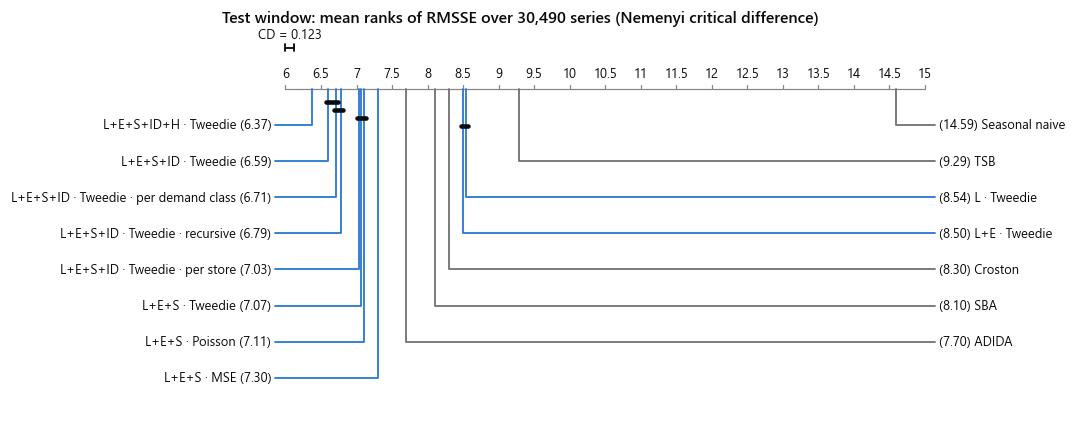

,mean rank,RMSSE mean test,WRMSSE test
L+E+S+ID+H · Tweedie,6.375,0.748,0.568
L+E+S+ID · Tweedie,6.594,0.750,0.572
L+E+S+ID · Tweedie · per demand class,6.710,0.751,0.577
L+E+S+ID · Tweedie · recursive,6.786,0.753,0.613
L+E+S+ID · Tweedie · per store,7.033,0.752,0.565
L+E+S · Tweedie,7.067,0.752,0.602
L+E+S · Poisson,7.105,0.752,0.625
L+E+S · MSE,7.305,0.753,0.618
ADIDA,7.700,0.762,0.945
SBA,8.100,0.771,0.961


In [10]:
CD_MODELS = ["Seasonal naive", "Croston", "SBA", "TSB", "ADIDA"] + [m for m in GLOBAL if m.endswith(T)] + [
    "L+E+S · MSE", "L+E+S · Poisson", f"{MAIN} · per store", f"{MAIN} · per demand class", f"{MAIN} · recursive"]
fn = S.friedman_nemenyi(rmsse[CD_MODELS])
ranks = fn["mean_ranks"].to_frame("mean rank")
ranks["RMSSE mean test"] = summary.loc[ranks.index, "RMSSE mean test"]
ranks["WRMSSE test"] = summary.loc[ranks.index, "WRMSSE test"]
ranks.to_csv(RESULTS / "friedman_ranks.csv")
print(f"Friedman chi2 = {fn['chi2']:,.0f}, p = {fn['p']:.3g}; Nemenyi CD = {fn['cd']:.3f} ({len(CD_MODELS)} models, {len(rmsse):,} series)")
fig, ax = plt.subplots(figsize=(9, 4.6))
S.plot_cd_diagram(ax, fn["mean_ranks"], fn["cd"], {m: (SERIES[0] if m in XGB else "0.45") for m in CD_MODELS})
ax.set_title("Test window: mean ranks of RMSSE over 30,490 series (Nemenyi critical difference)", loc="left", fontsize=10.5)
savefig(fig, "cd_diagram_test", subdir="evaluation")
plt.show()
ranks

**Seeds.** The main model and L+E+S+ID+H were trained with five seeds (the seed changes the row and column subsampling and
the horizons drawn per origin). Differences between models that are smaller than the spread below cannot
be told apart from the effect of the seed.

In [11]:
def seed_table(name):
    key = [k for k in raw.files if "_seed" not in k and not k.startswith(("benchmark_", "sample_", "backtest_")) and label(k) == name][0]
    runs = {0: raw[key], **{int(k.rsplit("seed", 1)[1]): f for k, f in seeds_fc.items() if k.startswith(key + "_seed")}}
    vbest = json.loads((ROOT / "results" / "global_xgb" / key / "best.json").read_text())
    vseeds = pd.DataFrame({0: {"WRMSSE": vbest["wrmsse"]}} | {s["seed"]: {"WRMSSE": s["wrmsse"]} for s in json.loads(
        (ROOT / "results" / "global_xgb" / key / "seeds.json").read_text())}).T
    t = pd.DataFrame({s: {"WRMSSE valid": vseeds.loc[s, "WRMSSE"], "WRMSSE test": ev_test.wrmsse(f)["all"],
                          **{f"{LEVEL_NAMES[k]} test": ev_test.wrmsse(f)[k] for k in (1, 3, 8, 12)},
                          "RMSSE mean test": ev_test.bottom(f)["rmsse"].mean()} for s, f in sorted(runs.items())}).T
    return pd.concat([t, t.agg(["mean", "std", "min", "max"])])


seeds = pd.concat({m: seed_table(m) for m in [BEST, EXTRA]}, names=["variant", "seed"])
seeds.to_csv(RESULTS / "seeds_test.csv")
seeds.style.format("{:.4f}")

## 7. Where the classical methods still win (Section 7.10)

Series on which a classical method has a lower RMSSE than the main model, by demand class and by
how much of the history is zero. The level table of Section 2 gives the other side: the levels on which the
classical methods are closest.

In [12]:
classical = rmsse[["Croston", "SBA", "TSB", "ADIDA"]].min(axis=1)  # best of the four on each series, an upper bound for them
zero_bin = pd.cut(stats["zero_share"], [0, 0.5, 0.7, 0.8, 0.9, 0.95, 1.0], include_lowest=True)
tbl = {}
for name, key in [("demand class", pd.Series(cls)), ("share of zero days in the history", zero_bin)]:
    g = pd.DataFrame({"series": 1, "ADIDA better": rmsse["ADIDA"] < rmsse[BEST], "TSB better": rmsse["TSB"] < rmsse[BEST],
                      "best of four intermittent methods better": classical < rmsse[BEST],
                      f"RMSSE {BEST}": rmsse[BEST], "RMSSE ADIDA": rmsse["ADIDA"]}).groupby(key.to_numpy(), observed=True)
    t = g.mean()
    t["series"] = g["series"].sum()
    tbl[name] = t
where = pd.concat(tbl)
where.to_csv(RESULTS / "where_classical_wins_test.csv")
flat = (test[BEST].std(axis=1) < 1e-6).mean()
print(f"ADIDA has a lower RMSSE than {BEST} on {(rmsse['ADIDA'] < rmsse[BEST]).mean():.1%} of all series")
where.style.format("{:.3f}").format("{:,.0f}", subset=["series"]).format(
    "{:.1%}", subset=["ADIDA better", "TSB better", "best of four intermittent methods better"])

ADIDA has a lower RMSSE than L+E+S+ID · Tweedie on 42.7% of all series


**A combination.** The mean of the forecasts of the main model and of a classical method, with equal
weights. The classical method is the one with the lowest mean RMSSE on the validation window, so nothing
is chosen on the test window.

In [13]:
partner = summary.loc[list(BM.values()), "RMSSE mean valid"].idxmin()
combo = {"valid": (valid[BEST] + valid[partner]) / 2, "test": (test[BEST] + test[partner]) / 2}
rows_ = {}
for name, fv, ft in [(BEST, valid[BEST], test[BEST]), (partner, valid[partner], test[partner]),
                     (f"Mean of {BEST} and {partner}", combo["valid"], combo["test"])]:
    wt, bt = ev_test.wrmsse(ft), ev_test.bottom(ft)["rmsse"]
    rows_[name] = {"WRMSSE valid": ev_valid.wrmsse(fv)["all"], "WRMSSE test": wt["all"], "Total": wt[1], "Item × store": wt[12],
                   "RMSSE mean valid": ev_valid.bottom(fv)["rmsse"].mean(), "RMSSE mean test": bt.mean(),
                   **{c: bt[cls == c].mean() for c in CLASSES},
                   f"better than {BEST} (share of series)": (bt.to_numpy() < rmsse[BEST].to_numpy()).mean()}
combination = pd.DataFrame(rows_).T
combination.to_csv(RESULTS / "combination_test.csv")
print("classical method of the combination (chosen on the validation window):", partner)
combination.style.format("{:.3f}")

classical method of the combination (chosen on the validation window): ADIDA


,WRMSSE valid,WRMSSE test,Total,Item × store,RMSSE mean valid,RMSSE mean test,smooth,erratic,intermittent,lumpy,better than L+E+S+ID · Tweedie (share of series)
L+E+S+ID · Tweedie,0.571,0.572,0.305,0.834,0.739,0.750,0.719,0.691,0.765,0.709,0.000
ADIDA,1.066,0.945,0.901,0.874,0.753,0.762,0.751,0.721,0.773,0.726,0.427
Mean of L+E+S+ID · Tweedie and ADIDA,0.768,0.667,0.455,0.843,0.742,0.752,0.726,0.698,0.766,0.713,0.499


## 8. Earlier windows (robustness)

One test window of 28 days is a small basis. As a check, the main models are evaluated on three earlier
28-day windows (01.02.–28.02.2016., 29.02.–27.03.2016., 28.03.–24.04.2016.) in the same way: each model is trained again on
the data up to the start of the window, with the hyperparameters and the number of rounds of its tuned
version, and forecasts the window 7 days at a time. The classical methods are recomputed from the history
up to each origin. The hyperparameters were chosen with later data than these windows, so the windows are
not as clean as the test window; the validation window (on which the models were tuned) is shown for
reference and is left out of the means.

A series with no sale before an origin is forecast as zero by every model. The mean RMSSE of a window is
over the series that have sold before it.

In [14]:
import evaluation as E

BT = RUNS / "backtest"
first_sale = stats["first_sale"].to_numpy()
windows = {}
for T in sorted(E.BACKTEST_ORIGINS):
    if not (BT / f"d{T}").exists():
        continue
    ev = M.Evaluator.for_origin(T, (T + 1, T + 28))
    started = np.repeat(first_sale[:, None] <= (T + m5.HORIZON * np.arange(m5.EVAL_WEEKS))[None, :], m5.HORIZON, axis=1)
    fcs = {BM[m]: raw[f"backtest_d{T}_benchmark_{m}"] for m in BM}
    fcs |= {label(f.stem): np.load(f) for f in sorted(RUNS.glob(f"backtest*/d{T}/*.npy"))}
    active = first_sale <= T
    res = {}
    for name, f in fcs.items():
        f = np.where(started, np.nan_to_num(f), 0)
        with np.errstate(divide="ignore", invalid="ignore"):
            r = ev.bottom(f)["rmsse"].to_numpy()
            res[name] = {"WRMSSE": ev.wrmsse(f)["all"], "RMSSE mean": r[active & np.isfinite(r)].mean()}
    windows[m5.window_name(T + 1, T + 28)] = pd.DataFrame(res).T
assert windows, "run the Kaggle job 'backtest' and fetch it first"
models_bt = [m for m in ORDER if m in next(iter(windows.values())).index]
windows["validation (tuned)"] = summary.loc[models_bt, ["WRMSSE valid", "RMSSE mean valid"]].set_axis(["WRMSSE", "RMSSE mean"], axis=1)
windows["test"] = summary.loc[models_bt, ["WRMSSE test", "RMSSE mean test"]].set_axis(["WRMSSE", "RMSSE mean"], axis=1)
bt = pd.concat({w: t.loc[models_bt] for w, t in windows.items()}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
clean = [w for w in windows if not w.startswith("validation")]
for measure in ["WRMSSE", "RMSSE mean"]:
    bt[(measure, "mean without validation")] = bt[measure][clean].mean(axis=1)
bt = bt[[(m, w) for m in ["WRMSSE", "RMSSE mean"] for w in list(windows) + ["mean without validation"]]]
bt.to_csv(RESULTS / "windows.csv")
bt.style.format("{:.3f}").background_gradient(cmap="Blues_r", axis=0)

c:\Users\ilin.j\Documents\MasterThesis\src\metrics.py:67: RuntimeWarning: invalid value encountered in divide
  return (change * started).sum(axis=1) / started.sum(axis=1)


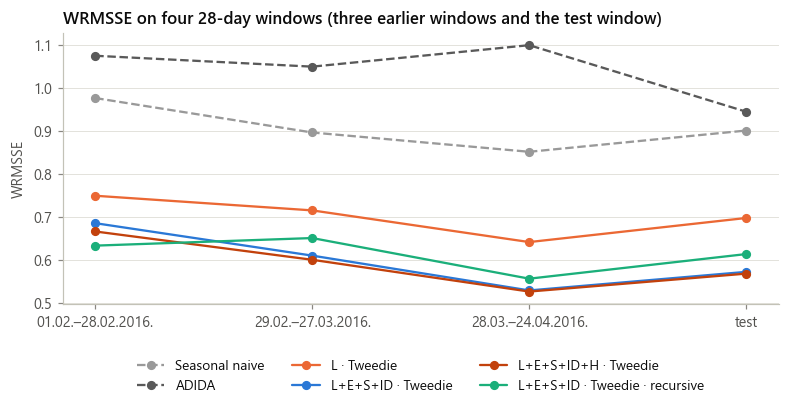

,01.02.–28.02.2016.,29.02.–27.03.2016.,28.03.–24.04.2016.,test
L+E+S+ID · Tweedie: WRMSSE,0.685,0.610,0.529,0.572
best classical method: WRMSSE,0.977,0.897,0.852,0.901
L+E+S+ID · Tweedie: RMSSE mean,0.705,0.708,0.714,0.750
best classical method: RMSSE mean,0.716,0.721,0.730,0.762
direct − recursive (WRMSSE),+0.052,-0.041,-0.027,-0.041
all series − per store (WRMSSE),+0.022,-0.017,-0.024,+0.007
L+E+S+ID+H − L+E+S+ID (WRMSSE),-0.019,-0.010,-0.003,-0.004
L+E+S+ID − L+E+S (WRMSSE),-0.094,-0.039,-0.045,-0.030
L+E − L (WRMSSE),-0.014,-0.043,-0.074,-0.076
Tweedie − MSE at L+E+S (WRMSSE),+0.062,-0.010,+0.004,-0.016


In [15]:
W = bt["WRMSSE"][clean]
R = bt["RMSSE mean"][clean]
best_classical_w = W.loc[[m for m in models_bt if m in BM.values()]].min()
best_classical_r = R.loc[[m for m in models_bt if m in BM.values()]].min()
checks = pd.DataFrame({
    f"{BEST}: WRMSSE": W.loc[BEST], "best classical method: WRMSSE": best_classical_w,
    f"{BEST}: RMSSE mean": R.loc[BEST], "best classical method: RMSSE mean": best_classical_r,
    "direct − recursive (WRMSSE)": W.loc[MAIN] - W.loc[f"{MAIN} · recursive"],
    "all series − per store (WRMSSE)": W.loc[MAIN] - W.loc[f"{MAIN} · per store"],
    "L+E+S+ID+H − L+E+S+ID (WRMSSE)": W.loc["L+E+S+ID+H · Tweedie"] - W.loc[MAIN],
    "L+E+S+ID − L+E+S (WRMSSE)": W.loc[MAIN] - W.loc["L+E+S · Tweedie"],
    "L+E − L (WRMSSE)": W.loc["L+E · Tweedie"] - W.loc["L · Tweedie"],
    "Tweedie − MSE at L+E+S (WRMSSE)": W.loc["L+E+S · Tweedie"] - W.loc["L+E+S · MSE"],
    "Tweedie − Poisson at L+E+S (WRMSSE)": W.loc["L+E+S · Tweedie"] - W.loc["L+E+S · Poisson"]}).T
checks.to_csv(RESULTS / "windows_checks.csv")
fig, ax = plt.subplots(figsize=(8.4, 3.2))
SHOW_BT = {"Seasonal naive": "0.6", "ADIDA": "0.35", "L · Tweedie": SERIES[1], BEST: SERIES[0], EXTRA: "#c2410c",
           f"{MAIN} · recursive": SERIES[2]}
for m, color in SHOW_BT.items():
    ax.plot(range(len(clean)), W.loc[m].to_numpy(), color=color, marker="o", ms=5, label=m, ls="--" if m in BM.values() else "-")
ax.set_xticks(range(len(clean)), clean)
ax.set_ylabel("WRMSSE")
ax.set_title("WRMSSE on four 28-day windows (three earlier windows and the test window)")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.16))
savefig(fig, "windows", subdir="evaluation")
plt.show()
checks.style.format("{:+.3f}").format("{:.3f}", subset=pd.IndexSlice[checks.index[:4], :])

## Key findings

The numbers of points 1–9 are from the test window, which no model has seen.

1. **Global XGBoost against the classical methods (7.1).** The main model (L+E+S+ID, Tweedie, the variant
   with the lowest validation WRMSSE among those fixed before the test window was opened) has WRMSSE 0.572 on
   the test window, against 0.901 for the seasonal naive method and 0.945 for ADIDA. Its validation score was
   0.571, so the tuning did not overfit the validation window. On single series the gain is small: mean RMSSE
   0.750 against 0.762 for ADIDA, and a lower RMSSE on 57% of the series.
2. **The classical methods were not held back by their settings.** Simple exponential smoothing (0.768) is
   level with TSB (0.766), and choosing the smoothing constants for each series separately changes the mean
   RMSSE by 0.003 or less (TSB 0.763, exponential smoothing 0.765, SBA 0.771). ADIDA with its fixed constant
   stays the best classical method on single series (0.762), the seasonal naive method on the hierarchy.
3. **Inputs (7.4).** WRMSSE falls with every group: 0.70 (L), 0.62 (L+E), 0.60 (L+E+S), 0.572 (L+E+S+ID),
   0.568 (L+E+S+ID+H). The
   inputs known in advance bring the largest gain, and almost all of it on the aggregated levels: the mean
   RMSSE of single series does not change from L to L+E (0.759) and falls to 0.752 and 0.750 with the
   statistics and the identifiers. A model with lags only is no better than ADIDA on single series (lower
   RMSSE on 47% of them).
   **The sales of the higher levels (group H), added last, help less than the validation window suggested.** On the
   validation window they lowered WRMSSE by 0.016, on the test window by 0.004, which is within the spread
   between seeds (0.563–0.575 for L+E+S+ID+H, 0.568–0.573 for L+E+S+ID). The sign is the same in all four
   clean windows (−0.019, −0.010, −0.003, −0.004), and the gain on the test window is at the bottom of the
   hierarchy (item 0.858 against 0.871, mean RMSSE of single series 0.748 against 0.750, better on 53% of the
   series), so the group helps a little and consistently, but far less than the identifiers. It is therefore
   reported as an additional step and does not replace the main model.
4. **Loss (7.3).** No loss wins consistently: Tweedie is best with L+E+S (0.602 against 0.618 and 0.625), MSE
   with L, Poisson with L+E, and the differences in mean RMSSE are 0.001 or less. The loss matters far less
   than the inputs.
5. **Pooling (7.2).** On all series, one model, one model per store and one per demand class are within 0.01
   of each other in WRMSSE (0.565–0.577 with L+E+S+ID; the partially global models were built on L+E+S+ID, not
   on L+E+S+ID+H) and within 0.002 in mean RMSSE; the model on all series
   has the best mean rank. Without the identifiers, models per store are better than one model (0.584 against
   0.602). On the sample of 1,000 series the models per series are clearly the worst XGBoost models: mean
   RMSSE 0.75 against 0.71–0.72 for the model on all series, which is better on 59–64% of the series
   (significant for every input set), and they are worse than ADIDA (0.738, better on 53% of the series).
   Their validation score of 0.64 was selection bias. A model trained on the 1,000 series alone matches the
   model on all series (differences of 0.002 or less, not significant): for single series it is pooling
   itself that helps, not the number of pooled series beyond a thousand.
6. **By level and by class (7.5, 7.6).** The advantage over the classical methods is largest at the top of
   the hierarchy (total: 0.31 against 0.64 for the seasonal naive method) and smallest at the bottom
   (item × store: 0.834 against 0.874 for ADIDA). By demand class the gain in mean RMSSE over ADIDA is 0.03
   for smooth and erratic series, 0.017 for lumpy and 0.008 for intermittent series.
7. **Strategy (7.7).** The recursive model is worse than the direct one on the test window (WRMSSE 0.613
   against 0.572 with L+E+S+ID; 0.666 against 0.602 with L+E+S), although it was better on the validation window (0.534
   against 0.571). Its validation advantage did not carry over.
8. **Significance and stability (7.9).** All planned comparisons are significant after the Holm correction,
   which with 30,490 series says little; the sizes of the differences are in the table. In the Friedman–Nemenyi
   ranking the XGBoost models with L+E+S or more inputs are ahead of every classical method (L+E+S+ID+H first,
   the main model second), but ADIDA, SBA and Croston rank ahead of the XGBoost models with L and L+E. Five
   seeds of the main model give WRMSSE 0.568–0.573 and the same mean RMSSE to three decimals (0.750); five
   seeds of L+E+S+ID+H give 0.563–0.575 and 0.748.
9. **Where the classical methods still win (7.10).** ADIDA has a lower RMSSE than the main model on 43%
   of all series and on 45% of the intermittent ones; the share grows with the share of zero days, from 35%
   (under half of the days zero) to 54% (90–95% zero). On very sparse series the two are practically tied.
   **Averaging the two does not help:** the mean of the forecasts of the main model and ADIDA has a mean
   RMSSE of 0.752 (0.750 for the model alone), is better than the model on half of the series, and loses the
   aggregated levels (WRMSSE 0.667). ADIDA wins on single series by chance of the window rather than
   through information the model lacks.
10. **Earlier windows (robustness).** On three earlier 28-day windows the picture of the test window holds
    where it matters. The main model beats the best classical method in every window, on the hierarchy
    (WRMSSE 0.53–0.69 against 0.85–0.98) and on single series (mean RMSSE 0.705–0.714 against 0.716–0.730).
    The order of the input sets is the same in all four windows: the inputs known in advance lower WRMSSE by
    0.01–0.08, the identifiers by 0.03–0.09 and the sales of the higher levels by 0.003–0.019. The direct model is better than the recursive one in three
    windows of four (mean WRMSSE 0.599 against 0.613), which confirms that the validation window was the
    exception. Two differences are not stable: the sign of the difference between the losses changes from
    window to window (Tweedie is 0.06 worse than MSE in the earliest window), and so does the one between
    one model and models per store. The level of the errors also varies between windows (0.53–0.69 for the
    main model), more than most differences between XGBoost variants.
11. **Limits.** L+E+S+ID+H was added after the test window had been opened for the other models; it was
    tuned on the validation window only, its test score was not used for any choice, and it is not the main
    model, although its validation score is the lowest. The earlier windows
    use hyperparameters chosen with later data; 30 tuning trials per variant;
    the partially global and recursive models were not tuned; the models per series exist for 1,000 series
    only.